# Week 4 – Predictive Modeling and Performance Evaluation
### Next-Day Adjusted Closing Price Forecasting for Infosys, Reliance Industries and TCS

**Project:** Financial Market Analysis Internship – Week 4

This notebook builds and evaluates a supervised regression model that predicts the **next trading day's adjusted closing price** of three Indian large-cap stocks. A separate Linear Regression model is trained for each company and compared against a naive persistence baseline on a chronologically held-out test set.

**Notebook outline**

1. Project Title and Overview
2. Objective
3. Dataset Description
4. Required Libraries
5. Data Loading and Initial Inspection
6. Feature Engineering
7. Target Variable Definition
8. Feature Selection
9. Handling Missing Values
10. Chronological Train-Test Split
11. Model Selection and Pipeline
12. Training Separate Models for Each Company
13. Generating Predictions
14. Naive Baseline Prediction
15. Model Evaluation Metrics
16. Performance Comparison
17. Actual vs. Predicted Visualization
18. Residual Analysis
19. Results and Key Observations
20. Limitations and Future Improvements
21. Final Conclusion

## 2. Objective

Predict the **next trading day's adjusted closing price** for Infosys, Reliance Industries and Tata Consultancy Services (TCS). This is a supervised regression problem.

The prediction is assumed to be made **after the current trading day's market data becomes available**, so every feature uses information from day *t* or earlier, and the target is the adjusted close on the next trading day (*t* + 1).

The central question is not only "how accurate is Linear Regression?" but also "does it improve on the simplest possible forecast – tomorrow's price equals today's price?"

## 3. Dataset Description

| Item | Description |
|---|---|
| Source | Yahoo Finance data prepared and cleaned in the earlier project weeks |
| File | `combined_cleaned_data.csv` |
| Companies | Infosys (`INFY.NS`), Reliance Industries (`RELIANCE.NS`), Tata Consultancy Services (`TCS.NS`) |
| Observations | 2,220 in total – 740 per company |
| Date range | 1 November 2023 to 30 October 2026 |

**Columns used by the model**

- `adj_close` – adjusted closing price (basis for the target and the price-lag features)
- `volume` – shares traded
- `daily_return` – daily percentage return (from the earlier weeks)
- `rolling_volatility` – 20-day rolling standard deviation of `daily_return` (from the earlier weeks)
- `ticker`, `company`, `date` – identifiers and ordering

The file also contains other columns from earlier weeks (open, high, low, dividends, outlier flags, etc.); these are not used as model inputs.

**Naming note:** features named `current_close`, `close_lag_*` are built from the **adjusted** close (`adj_close`), not the raw `close` column.

## 4. Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.3f}".format)

# Folder where the figures generated below are also saved (used in the written report)
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

## 5. Data Loading and Initial Inspection

The data is sorted by `ticker` and `date` so that every lag/lead operation below respects time order within each company. The checks confirm 740 rows per company, no duplicate company-date records, and show where missing values exist in the raw file.

In [2]:
df = pd.read_csv(
    "combined_cleaned_data.csv",
    parse_dates=["date"]
)

df = df.sort_values(
    ["ticker", "date"]
).reset_index(drop=True)

print("Dataset shape:", df.shape)
print("Date range:", df["date"].min(), "to", df["date"].max())

Dataset shape: (2220, 18)
Date range: 2023-11-01 00:00:00 to 2026-10-30 00:00:00


In [3]:
display(df.head())

display(df[["company", "ticker"]].drop_duplicates())

display(df.groupby("company").size())

display(df.isnull().sum())

print(
    "Duplicate company-date records:",
    df.duplicated(subset=["ticker", "date"]).sum()
)

Duplicate company-date records: 0


,date,adj_close,close,dividends,high,low,open,stock_splits,volume,ticker,company,daily_return,return_outlier,volume_outlier,price_change,normalized_price,rolling_volatility,cumulative_return
0,2023-11-01,"1,219.962","1,354.150",0.000,"1,377.450","1,351.650","1,373.050",0.000,3090672,INFY.NS,Infosys,NaN,False,False,NaN,100.000,NaN,0.000
1,2023-11-02,"1,234.376","1,370.150",0.000,"1,376.300","1,361.650","1,370.000",0.000,3758060,INFY.NS,Infosys,1.182,False,False,14.414,101.182,NaN,1.182
2,2023-11-03,"1,251.403","1,389.050",0.000,"1,392.000","1,377.750","1,380.050",0.000,3349045,INFY.NS,Infosys,1.379,False,False,17.027,102.577,NaN,2.577
3,2023-11-06,"1,264.241","1,403.300",0.000,"1,407.250","1,390.800","1,393.900",0.000,2736381,INFY.NS,Infosys,1.026,False,False,12.838,103.630,NaN,3.630
4,2023-11-07,"1,265.142","1,404.300",0.000,"1,405.900","1,394.850","1,400.000",0.000,2272209,INFY.NS,Infosys,0.071,False,False,0.901,103.703,NaN,3.703


,company,ticker
0,Infosys,INFY.NS
740,Reliance Industries,RELIANCE.NS
1480,Tata Consultancy Services,TCS.NS


company
Infosys                      740
Reliance Industries          740
Tata Consultancy Services    740
dtype: int64

date                   0
adj_close              0
close                  0
dividends              0
high                   0
low                    0
open                   0
stock_splits           0
volume                 0
ticker                 0
company                0
daily_return           3
return_outlier         0
volume_outlier         0
price_change           3
normalized_price       0
rolling_volatility    60
cumulative_return      0
dtype: int64

The only missing values in the raw file are in `daily_return` (the first row of each company, 3 in total) and `rolling_volatility` (the first 20 rows of each company, 60 in total). They arise from the return and 20-day rolling-window calculations and are handled in Section 9.

## 6. Feature Engineering

All features are built **separately for each ticker** using `groupby("ticker")`, so lagged values never leak across companies. `shift(k)` brings the value from *k* trading days earlier into the current row.

| Feature | Meaning |
|---|---|
| `current_close` | Adjusted close on day *t* |
| `close_lag_1`, `close_lag_2`, `close_lag_5` | Adjusted close 1, 2 and 5 trading days earlier |
| `current_volume`, `volume_lag_1` | Volume on day *t* and *t* − 1 |
| `current_return`, `return_lag_1` | Daily return on day *t* and *t* − 1 |
| `current_volatility`, `volatility_lag_1` | 20-day rolling volatility on day *t* and *t* − 1 |

In [4]:
model_df = df.copy()

grouped = model_df.groupby("ticker")

model_df["current_close"] = grouped["adj_close"].shift(0)
model_df["close_lag_1"] = grouped["adj_close"].shift(1)
model_df["close_lag_2"] = grouped["adj_close"].shift(2)
model_df["close_lag_5"] = grouped["adj_close"].shift(5)

model_df["current_volume"] = grouped["volume"].shift(0)
model_df["volume_lag_1"] = grouped["volume"].shift(1)

model_df["current_return"] = grouped["daily_return"].shift(0)
model_df["return_lag_1"] = grouped["daily_return"].shift(1)

model_df["current_volatility"] = grouped["rolling_volatility"].shift(0)
model_df["volatility_lag_1"] = grouped["rolling_volatility"].shift(1)

display(
    model_df[[
        "date", "company", "current_close", "close_lag_1", "close_lag_2",
        "close_lag_5", "current_volume", "volume_lag_1", "current_return",
        "return_lag_1", "current_volatility", "volatility_lag_1"
    ]].head(8)
)

,date,company,current_close,close_lag_1,close_lag_2,close_lag_5,current_volume,volume_lag_1,current_return,return_lag_1,current_volatility,volatility_lag_1
0,2023-11-01,Infosys,"1,219.962",NaN,NaN,NaN,3090672,NaN,NaN,NaN,NaN,NaN
1,2023-11-02,Infosys,"1,234.376","1,219.962",NaN,NaN,3758060,"3,090,672.000",1.182,NaN,NaN,NaN
2,2023-11-03,Infosys,"1,251.403","1,234.376","1,219.962",NaN,3349045,"3,758,060.000",1.379,1.182,NaN,NaN
3,2023-11-06,Infosys,"1,264.241","1,251.403","1,234.376",NaN,2736381,"3,349,045.000",1.026,1.379,NaN,NaN
4,2023-11-07,Infosys,"1,265.142","1,264.241","1,251.403",NaN,2272209,"2,736,381.000",0.071,1.026,NaN,NaN
5,2023-11-08,Infosys,"1,253.160","1,265.142","1,264.241","1,219.962",3550635,"2,272,209.000",-0.947,0.071,NaN,NaN
6,2023-11-09,Infosys,"1,238.565","1,253.160","1,265.142","1,234.376",5498051,"3,550,635.000",-1.165,-0.947,NaN,NaN
7,2023-11-10,Infosys,"1,233.205","1,238.565","1,253.160","1,251.403",2943649,"5,498,051.000",-0.433,-1.165,NaN,NaN


## 7. Target Variable Definition

The target, `target_next_close`, is the adjusted close of the **next trading day**: `adj_close` shifted by −1 within each company. `target_date` stores the calendar date of that next trading day so predictions can be plotted against the date they refer to.

Because the last row of each company has no "next day", its target is missing and it is removed in Section 9.

In [5]:
model_df["target_next_close"] = grouped["adj_close"].shift(-1)
model_df["target_date"] = grouped["date"].shift(-1)

display(
    model_df[["date", "company", "current_close", "target_date", "target_next_close"]].head(5)
)

,date,company,current_close,target_date,target_next_close
0,2023-11-01,Infosys,"1,219.962",2023-11-02,"1,234.376"
1,2023-11-02,Infosys,"1,234.376",2023-11-03,"1,251.403"
2,2023-11-03,Infosys,"1,251.403",2023-11-06,"1,264.241"
3,2023-11-06,Infosys,"1,264.241",2023-11-07,"1,265.142"
4,2023-11-07,Infosys,"1,265.142",2023-11-08,"1,253.160"


## 8. Feature Selection

Ten features are used. They combine recent price history, trading activity, short-term return and volatility. The features were selected by design rather than through an automated selection procedure, and no feature-importance analysis has been performed.

Adjacent price lags (`current_close`, `close_lag_1`, `close_lag_2`) are likely to be strongly correlated with one another; this is discussed under limitations.

In [6]:
features = [
    "current_close",
    "close_lag_1",
    "close_lag_2",
    "close_lag_5",
    "current_volume",
    "volume_lag_1",
    "current_return",
    "return_lag_1",
    "current_volatility",
    "volatility_lag_1"
]

target = "target_next_close"

print("Number of features:", len(features))

Number of features: 10


## 9. Handling Missing Values

Rows are dropped when any selected feature, the target or the target date is missing. Per company this removes:

- the first 21 rows – the 20-day rolling volatility needs 20 return observations and `volatility_lag_1` needs one more day, and
- the last row – it has no next-day target.

That is 22 rows per company, 66 in total. No imputation is used, so no artificial values enter the data.

In [7]:
model_data = model_df.dropna(
    subset=features + [target, "target_date"]
).copy()

print("Original observations:", len(model_df))
print("Usable observations:", len(model_data))
print("Removed observations:", len(model_df) - len(model_data))

display(model_data.groupby("company").size())

display(model_data[features + [target]].isnull().sum())

Original observations: 2220
Usable observations: 2154
Removed observations: 66


company
Infosys                      718
Reliance Industries          718
Tata Consultancy Services    718
dtype: int64

current_close         0
close_lag_1           0
close_lag_2           0
close_lag_5           0
current_volume        0
volume_lag_1          0
current_return        0
return_lag_1          0
current_volatility    0
volatility_lag_1      0
target_next_close     0
dtype: int64

## 10. Chronological Train-Test Split

For each company the usable observations are ordered by date and split **80 : 20** – the first 80% for training and the most recent 20% for testing. The data is **not shuffled**: random shuffling would let the model train on future prices and test on past ones, which is unrealistic for forecasting and would overstate performance.

The "Testing period" printed below refers to the **prediction-origin dates** (the day on which features are observed). The corresponding target dates are shown in the following cell.

In [8]:
train_test_data = {}

for company in model_data["company"].unique():

    company_data = (
        model_data[model_data["company"] == company]
        .sort_values("date")
        .reset_index(drop=True)
    )

    split_index = int(len(company_data) * 0.80)

    train = company_data.iloc[:split_index]
    test = company_data.iloc[split_index:]

    train_test_data[company] = {
        "X_train": train[features],
        "X_test": test[features],
        "y_train": train[target],
        "y_test": test[target],
        "test_dates": test["target_date"]
    }

    print(f"\n{company}")
    print("Training observations:", len(train))
    print("Testing observations:", len(test))
    print("Training period:", train["date"].min(), "to", train["date"].max())
    print("Testing period:", test["date"].min(), "to", test["date"].max())


Infosys
Training observations: 574
Testing observations: 144
Training period: 2023-12-04 00:00:00 to 2026-03-30 00:00:00
Testing period: 2026-04-01 00:00:00 to 2026-10-29 00:00:00

Reliance Industries
Training observations: 574
Testing observations: 144
Training period: 2023-12-04 00:00:00 to 2026-03-30 00:00:00
Testing period: 2026-04-01 00:00:00 to 2026-10-29 00:00:00

Tata Consultancy Services
Training observations: 574
Testing observations: 144
Training period: 2023-12-04 00:00:00 to 2026-03-30 00:00:00
Testing period: 2026-04-01 00:00:00 to 2026-10-29 00:00:00


In [9]:
for company, data in train_test_data.items():
    print(
        company,
        "| First target date:", data["test_dates"].min(),
        "| Last target date:", data["test_dates"].max()
    )

print("\nTotal training observations:", sum(len(d["X_train"]) for d in train_test_data.values()))
print("Total testing observations:", sum(len(d["X_test"]) for d in train_test_data.values()))

Infosys | First target date: 2026-04-02 00:00:00 | Last target date: 2026-10-30 00:00:00
Reliance Industries | First target date: 2026-04-02 00:00:00 | Last target date: 2026-10-30 00:00:00
Tata Consultancy Services | First target date: 2026-04-02 00:00:00 | Last target date: 2026-10-30 00:00:00

Total training observations: 1722
Total testing observations: 432


## 11. Model Selection and Pipeline

**Model:** Linear Regression – a simple, interpretable baseline model for regression, as suggested in the task brief.

**Preprocessing:** a `ColumnTransformer` applies `StandardScaler` to all ten features, and the transformer and regressor are chained in a scikit-learn `Pipeline`. Because the scaler lives inside the pipeline, it is **fitted on the training data only**, and the training mean and standard deviation are then reused to transform the test data – no test information leaks into preprocessing.

Standardisation puts features such as volume (millions) and returns (percent) on comparable scales. It does not change the predictions of ordinary Linear Regression in any material way, and it does not remove multicollinearity; it is included as a standard, leak-safe preprocessing step.

No hyperparameter tuning or cross-validation is performed in this notebook.

In [10]:
def build_pipeline():
    """Return a fresh StandardScaler + LinearRegression pipeline."""
    preprocessor = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), features)
        ],
        remainder="drop"
    )

    return Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ])

## 12. Training Separate Models for Each Company

Each company has its own price level and dynamics (for example, TCS trades at a substantially higher price level than Reliance), so a separate pipeline is fitted on each company's training set.

In [11]:
models = {}

for company, data in train_test_data.items():

    pipeline = build_pipeline()

    pipeline.fit(
        data["X_train"],
        data["y_train"]
    )

    models[company] = {"pipeline": pipeline}

    print(f"{company}: Model trained successfully.")

Infosys: Model trained successfully.
Reliance Industries: Model trained successfully.
Tata Consultancy Services: Model trained successfully.


## 13. Generating Predictions

Each fitted pipeline predicts the next-day adjusted close for its company's test observations. The first ten predictions per company are shown next to the actual value and the baseline (Section 14).

In [12]:
for company, data in train_test_data.items():
    models[company]["predictions"] = models[company]["pipeline"].predict(data["X_test"])

print("Predictions generated for:", ", ".join(models.keys()))

Predictions generated for: Infosys, Reliance Industries, Tata Consultancy Services


## 14. Naive Baseline Prediction

The **naive persistence baseline** predicts that tomorrow's adjusted close equals today's: `baseline = current_close`. It needs no training and is evaluated on exactly the same test observations as Linear Regression.

This is a meaningful benchmark because short-term stock prices tend to be highly persistent – today's price already contains most of the information relevant to tomorrow's price – so the baseline is often difficult to outperform.

In [13]:
for company, data in train_test_data.items():
    data["baseline"] = data["X_test"]["current_close"]

for company, data in train_test_data.items():

    results = pd.DataFrame({
        "Date": data["test_dates"].values,
        "Actual": data["y_test"].values,
        "Predicted": models[company]["predictions"],
        "Baseline": data["baseline"].values
    })

    print(f"\n{company}")
    display(results.head(10))


Infosys

Reliance Industries

Tata Consultancy Services


,Date,Actual,Predicted,Baseline
0,2026-04-02,"1,244.734","1,223.028","1,220.716"
1,2026-04-06,"1,249.901","1,246.721","1,244.734"
2,2026-04-07,"1,281.670","1,253.628","1,249.901"
3,2026-04-08,"1,288.177","1,280.932","1,281.670"
4,2026-04-09,"1,274.207","1,289.461","1,288.177"
5,2026-04-10,"1,236.792","1,274.608","1,274.207"
6,2026-04-13,"1,221.768","1,234.170","1,236.792"
7,2026-04-15,"1,249.040","1,223.170","1,221.768"
8,2026-04-16,"1,262.341","1,249.581","1,249.040"
9,2026-04-17,"1,261.862","1,263.512","1,262.341"


,Date,Actual,Predicted,Baseline
0,2026-04-02,"1,344.285","1,362.733","1,362.898"
1,2026-04-06,"1,298.695","1,351.689","1,344.285"
2,2026-04-07,"1,298.596","1,301.594","1,298.695"
3,2026-04-08,"1,341.597","1,306.158","1,298.596"
4,2026-04-09,"1,323.879","1,342.382","1,341.597"
5,2026-04-10,"1,343.986","1,328.717","1,323.879"
6,2026-04-13,"1,309.047","1,346.150","1,343.986"
7,2026-04-15,"1,337.914","1,313.720","1,309.047"
8,2026-04-16,"1,337.118","1,336.167","1,337.914"
9,2026-04-17,"1,358.718","1,345.677","1,337.118"


,Date,Actual,Predicted,Baseline
0,2026-04-02,"2,392.014","2,339.415","2,350.532"
1,2026-04-06,"2,414.659","2,381.375","2,392.014"
2,2026-04-07,"2,478.981","2,411.223","2,414.659"
3,2026-04-08,"2,497.916","2,464.553","2,478.981"
4,2026-04-09,"2,527.003","2,494.125","2,497.916"
5,2026-04-10,"2,463.852","2,521.744","2,527.003"
6,2026-04-13,"2,413.390","2,465.223","2,463.852"
7,2026-04-15,"2,493.719","2,422.140","2,413.390"
8,2026-04-16,"2,515.192","2,475.843","2,493.719"
9,2026-04-17,"2,519.682","2,510.833","2,515.192"


## 15. Model Evaluation Metrics

| Metric | Definition | Interpretation |
|---|---|---|
| **MAE** | mean(\|actual − predicted\|) | Average error in price units (₹); easy to interpret |
| **MSE** | mean((actual − predicted)²) | Squared error; penalises large misses heavily |
| **RMSE** | √MSE | Error in price units, more sensitive to large errors than MAE |
| **R²** | 1 − SSE / SST | Share of variance in actual prices explained; 1 is perfect |

Both Linear Regression and the baseline are scored on the same test targets. **A high R² does not by itself show that a model is better** – price levels are strongly autocorrelated, so even the naive baseline achieves a high R². The relevant comparison is the model against the baseline.

In [14]:
evaluation_results = []

for company, data in train_test_data.items():

    actual = data["y_test"]
    predicted = models[company]["predictions"]
    baseline = data["baseline"]

    evaluation_results.append({
        "Company": company,
        "Model": "Linear Regression",
        "MAE": mean_absolute_error(actual, predicted),
        "MSE": mean_squared_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    })

    evaluation_results.append({
        "Company": company,
        "Model": "Naive Baseline",
        "MAE": mean_absolute_error(actual, baseline),
        "MSE": mean_squared_error(actual, baseline),
        "RMSE": np.sqrt(mean_squared_error(actual, baseline)),
        "R2": r2_score(actual, baseline)
    })

evaluation_df = pd.DataFrame(evaluation_results)

display(
    evaluation_df.round(4)
)

,Company,Model,MAE,MSE,RMSE,R2
0,Infosys,Linear Regression,19.099,594.661,24.386,0.888
1,Infosys,Naive Baseline,18.220,574.146,23.961,0.892
2,Reliance Industries,Linear Regression,14.114,321.298,17.925,0.917
3,Reliance Industries,Naive Baseline,14.024,321.026,17.917,0.917
4,Tata Consultancy Services,Linear Regression,36.445,"2,391.187",48.900,0.892
5,Tata Consultancy Services,Naive Baseline,34.983,"2,332.648",48.297,0.894


**Worked example – first test prediction for each company.** The table shows how a single prediction is scored: the absolute error is |actual − prediction|.

In [15]:
example_rows = []

for company, data in train_test_data.items():
    actual = data["y_test"].iloc[0]
    lr_pred = models[company]["predictions"][0]
    base_pred = data["baseline"].iloc[0]

    example_rows.append({
        "Company": company,
        "Target date": data["test_dates"].iloc[0].date(),
        "Actual": actual,
        "LR prediction": lr_pred,
        "Baseline prediction": base_pred,
        "LR abs. error": abs(actual - lr_pred),
        "Baseline abs. error": abs(actual - base_pred)
    })

display(pd.DataFrame(example_rows))

,Company,Target date,Actual,LR prediction,Baseline prediction,LR abs. error,Baseline abs. error
0,Infosys,2026-04-02,"1,244.734","1,223.028","1,220.716",21.706,24.018
1,Reliance Industries,2026-04-02,"1,344.285","1,362.733","1,362.898",18.449,18.614
2,Tata Consultancy Services,2026-04-02,"2,392.014","2,339.415","2,350.532",52.600,41.483


## 16. Performance Comparison

The pivot table places Linear Regression and the naive baseline side by side. Next, the sanity check confirms that the metrics reproduce the verified values (rounded to three decimals).

In [16]:
comparison = evaluation_df.pivot(
    index="Company",
    columns="Model",
    values=["MAE", "RMSE", "R2"]
)

display(comparison.round(4))

MAE                             RMSE  \
Model                     Linear Regression Naive Baseline Linear Regression   
Company                                                                        
Infosys                              19.099         18.220            24.386   
Reliance Industries                  14.114         14.024            17.925   
Tata Consultancy Services            36.445         34.983            48.900   

                                                        R2                 
Model                     Naive Baseline Linear Regression Naive Baseline  
Company                                                                    
Infosys                           23.961             0.888          0.892  
Reliance Industries               17.917             0.917          0.917  
Tata Consultancy Services         48.297             0.892          0.894

In [17]:
# Sanity check against the verified Week 4 results (3 decimal places)
expected = {
    ("Infosys", "Linear Regression"):                (19.099,   594.661, 24.386, 0.888),
    ("Infosys", "Naive Baseline"):                   (18.220,   574.146, 23.961, 0.892),
    ("Reliance Industries", "Linear Regression"):    (14.114,   321.298, 17.925, 0.917),
    ("Reliance Industries", "Naive Baseline"):       (14.024,   321.026, 17.917, 0.917),
    ("Tata Consultancy Services", "Linear Regression"): (36.445, 2391.187, 48.900, 0.892),
    ("Tata Consultancy Services", "Naive Baseline"):    (34.983, 2332.648, 48.297, 0.894),
}

for (company, model_name), values in expected.items():
    row = evaluation_df[
        (evaluation_df["Company"] == company) & (evaluation_df["Model"] == model_name)
    ].iloc[0]
    got = tuple(round(row[m], 3) for m in ["MAE", "MSE", "RMSE", "R2"])
    assert got == values, f"{company} / {model_name}: {got} != {values}"

print("All metrics match the verified results.")

All metrics match the verified results.


Raw MAE and RMSE are in rupees, and the three stocks trade at different price levels, so they should **not** be compared directly across companies. The table below expresses MAE as a percentage of each company's mean test-period price, shows the Linear Regression − Baseline MAE gap, and counts the test days on which Linear Regression's absolute error was smaller than the baseline's.

In [18]:
scale_rows = []

for company, data in train_test_data.items():
    actual = data["y_test"].values
    lr_err = np.abs(actual - models[company]["predictions"])
    base_err = np.abs(actual - data["baseline"].values)

    scale_rows.append({
        "Company": company,
        "Mean test price": actual.mean(),
        "Min test price": actual.min(),
        "Max test price": actual.max(),
        "LR MAE (% of mean price)": 100 * lr_err.mean() / actual.mean(),
        "Baseline MAE (% of mean price)": 100 * base_err.mean() / actual.mean(),
        "LR MAE minus Baseline MAE": lr_err.mean() - base_err.mean(),
        "Days LR closer": int((lr_err < base_err).sum()),
        "Test days": len(actual),
        "LR closer (%)": 100 * (lr_err < base_err).mean()
    })

scale_df = pd.DataFrame(scale_rows)
display(scale_df)

,Company,Mean test price,Min test price,Max test price,LR MAE (% of mean price),Baseline MAE (% of mean price),LR MAE minus Baseline MAE,Days LR closer,Test days,LR closer (%)
0,Infosys,"1,097.822",963.235,"1,288.177",1.740,1.660,0.878,61,144,42.361
1,Reliance Industries,"1,294.244","1,158.000","1,456.864",1.091,1.084,0.090,71,144,49.306
2,Tata Consultancy Services,"2,268.809","1,961.362","2,547.988",1.606,1.542,1.461,60,144,41.667


## 17. Actual vs. Predicted Visualization

Each chart plots the actual next-day adjusted close, the Linear Regression prediction and the naive baseline over the test period, indexed by **target date**. Because the series are plotted at a daily scale, the predicted lines closely follow the actual price; the differences are visible mainly at turning points.

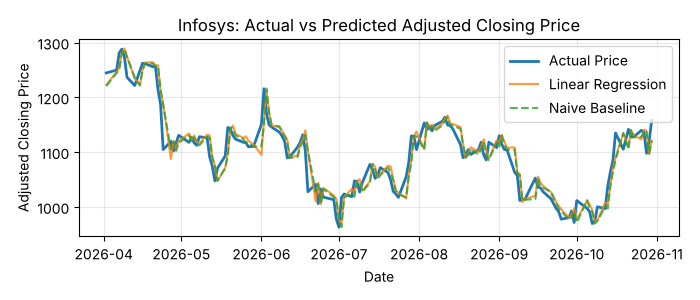

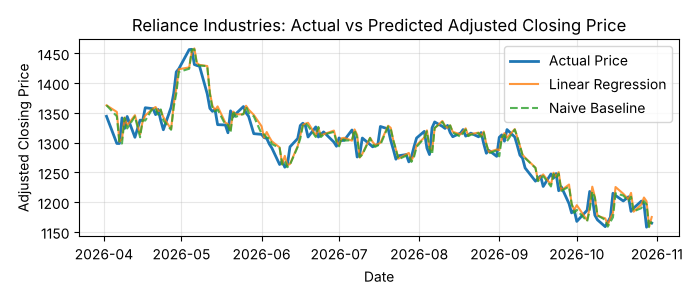

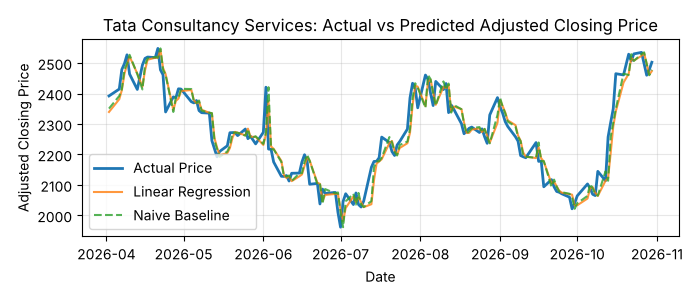

In [19]:
for company, data in train_test_data.items():

    plt.figure(figsize=(7, 3))

    plt.plot(
        data["test_dates"],
        data["y_test"].values,
        label="Actual Price",
        linewidth=2
    )

    plt.plot(
        data["test_dates"],
        models[company]["predictions"],
        label="Linear Regression",
        alpha=0.8
    )

    plt.plot(
        data["test_dates"],
        data["baseline"].values,
        label="Naive Baseline",
        alpha=0.8,
        linestyle="--"
    )

    plt.title(f"{company}: Actual vs Predicted Adjusted Closing Price")
    plt.xlabel("Date")
    plt.ylabel("Adjusted Closing Price")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"actual_vs_predicted_{company.replace(' ', '_')}.png", dpi=200)
    plt.show()

## 18. Residual Analysis

Residual = **Actual − Predicted** for Linear Regression. A negative residual means the model over-predicted; a positive residual means it under-predicted. In a well-specified model, residuals scatter around zero with no obvious pattern against the predicted value.

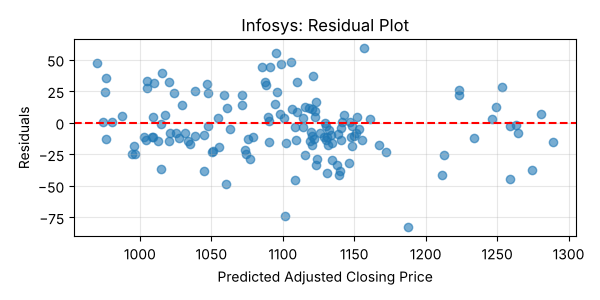

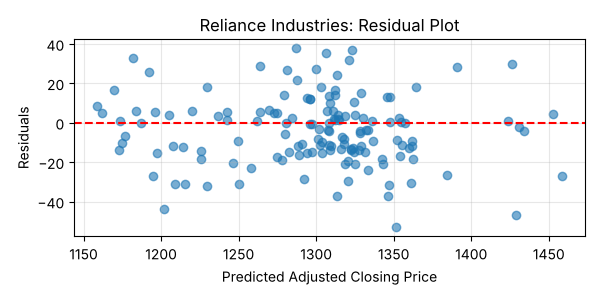

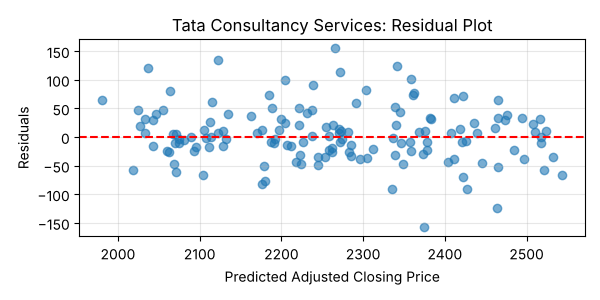

In [20]:
for company, data in train_test_data.items():

    actual = data["y_test"].values
    predicted = models[company]["predictions"]
    residuals = actual - predicted

    plt.figure(figsize=(6, 3))

    plt.scatter(
        predicted,
        residuals,
        alpha=0.6
    )

    plt.axhline(
        y=0,
        color="red",
        linestyle="--"
    )

    plt.title(f"{company}: Residual Plot")
    plt.xlabel("Predicted Adjusted Closing Price")
    plt.ylabel("Residuals")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"residuals_{company.replace(' ', '_')}.png", dpi=200)
    plt.show()

In [21]:
residual_summary = []

for company, data in train_test_data.items():

    actual = data["y_test"].reset_index(drop=True)
    predicted = pd.Series(models[company]["predictions"])

    residuals = actual - predicted

    residual_summary.append({
        "Company": company,
        "Mean Residual": residuals.mean(),
        "Residual Std Dev": residuals.std(),
        "Minimum Residual": residuals.min(),
        "Maximum Residual": residuals.max()
    })

residual_summary_df = pd.DataFrame(residual_summary)

display(residual_summary_df.round(4))

,Company,Mean Residual,Residual Std Dev,Minimum Residual,Maximum Residual
0,Infosys,-2.880,24.300,-82.762,58.953
1,Reliance Industries,-3.977,17.539,-52.993,37.719
2,Tata Consultancy Services,4.463,48.866,-157.370,154.898


**Largest errors.** The dates on which Linear Regression missed by the most (largest over- and under-predictions) are listed below, together with the naive baseline's prediction for the same day.

In [22]:
extreme_rows = []

for company, data in train_test_data.items():
    detail = pd.DataFrame({
        "Target date": data["test_dates"].values,
        "Actual": data["y_test"].values,
        "LR prediction": models[company]["predictions"],
        "Baseline prediction": data["baseline"].values
    })
    detail["Residual"] = detail["Actual"] - detail["LR prediction"]

    for label, idx in [("Largest over-prediction", detail["Residual"].idxmin()),
                       ("Largest under-prediction", detail["Residual"].idxmax())]:
        row = detail.loc[idx]
        extreme_rows.append({
            "Company": company,
            "Case": label,
            "Target date": row["Target date"].date(),
            "Actual": row["Actual"],
            "LR prediction": row["LR prediction"],
            "Baseline prediction": row["Baseline prediction"],
            "Residual": row["Residual"]
        })

display(pd.DataFrame(extreme_rows))

,Company,Case,Target date,Actual,LR prediction,Baseline prediction,Residual
0,Infosys,Largest over-prediction,2026-04-24,"1,104.835","1,187.597","1,187.129",-82.762
1,Infosys,Largest under-prediction,2026-06-02,"1,216.027","1,157.074","1,150.671",58.953
2,Reliance Industries,Largest over-prediction,2026-04-06,"1,298.695","1,351.689","1,344.285",-52.993
3,Reliance Industries,Largest under-prediction,2026-08-06,"1,325.000","1,287.281","1,280.000",37.719
4,Tata Consultancy Services,Largest over-prediction,2026-06-03,"2,217.687","2,375.057","2,420.688",-157.370
5,Tata Consultancy Services,Largest under-prediction,2026-06-02,"2,420.688","2,265.791","2,272.790",154.898


## 19. Results and Key Observations

All figures below come from the outputs above (test set: 144 observations per company).

| Company | Model | MAE | RMSE | R² |
|---|---|---:|---:|---:|
| Infosys | Linear Regression | 19.099 | 24.386 | 0.888 |
| Infosys | Naive Baseline | 18.220 | 23.961 | 0.892 |
| Reliance Industries | Linear Regression | 14.114 | 17.925 | 0.917 |
| Reliance Industries | Naive Baseline | 14.024 | 17.917 | 0.917 |
| TCS | Linear Regression | 36.445 | 48.900 | 0.892 |
| TCS | Naive Baseline | 34.983 | 48.297 | 0.894 |

1. **Linear Regression tracks the broad price movements** of all three companies; R² is between 0.888 and 0.917.
2. **The naive baseline is marginally better on MAE, MSE and RMSE for all three companies.** Linear Regression does not consistently outperform the persistence benchmark and should not be described as the better model on this evidence. R² is equal for Reliance (0.917) and slightly higher for the baseline for Infosys and TCS.
3. **Infosys:** MAE 19.099 vs 18.220 for the baseline (a gap of about 0.88). Linear Regression was closer than the baseline on 61 of 144 test days (42.4%). Relative to its mean test price, Infosys has the highest error of the three (MAE of about 1.74% of price).
4. **Reliance Industries:** MAE 14.114 vs 14.024 (a gap of about 0.09) – the two approaches are almost indistinguishable (Linear Regression was closer on 71 of 144 days, 49.3%). Reliance has the lowest errors both in rupees and relative to its mean test price (MAE of about 1.09% of price).
5. **TCS:** MAE 36.445 vs 34.983 (a gap of about 1.46; Linear Regression was closer on 60 of 144 days, 41.7%). TCS has the largest rupee errors and the most variable residuals (standard deviation 48.866, range −157.370 to 154.898), largely because it trades at a higher price level; relative to price its MAE is about 1.61%.
6. **Residuals** scatter around zero for all three companies, with no strong visible pattern against the predicted price; some large outliers exist (for example −82.762 for Infosys and −157.370 for TCS). Mean residuals are small relative to their standard deviations (Infosys −2.880, Reliance −3.977, TCS +4.463).
7. High R² reflects that price *levels* are strongly autocorrelated; the baseline achieves nearly the same R² without any model.

## 20. Limitations and Future Improvements

### Limitations

- Stock prices respond to unpredictable events (earnings, policy changes, global shocks) that price and volume history cannot capture.
- Adjacent price-lag features are probably highly correlated, so individual coefficients may be unstable. `StandardScaler` does not eliminate multicollinearity or make the model inherently more accurate.
- Linear Regression assumes a linear relationship between the features and the next-day price.
- The model is evaluated on a single chronological test period (about seven months); performance may differ in other market regimes.
- The persistence baseline is a strong benchmark for one-day-ahead prices, so small differences between the two should be interpreted cautiously. No statistical significance test was performed.
- The model is trained once on a fixed training window and is not re-estimated as new data arrives.

### What was implemented in this notebook

Feature engineering with per-company lags, a chronological 80:20 split, a StandardScaler + Linear Regression pipeline per company, a naive persistence baseline, MAE/MSE/RMSE/R² evaluation, and residual analysis.

### Proposed future work (not performed)

- Ridge or Lasso regression to handle correlated lag features.
- Additional financial indicators (for example moving averages or RSI).
- Walk-forward (rolling-origin) validation and evaluation across multiple periods.
- Nonlinear models, compared against the same persistence baseline.
- Feature-importance and error analysis, including the large-residual days.
- Modelling returns instead of price levels.

**Hyperparameter tuning, cross-validation and additional algorithms were not performed.**

## 21. Final Conclusion

A separate StandardScaler + Linear Regression pipeline was trained for each of Infosys, Reliance Industries and TCS to predict the next trading day's adjusted close, using a chronological 80:20 split (574 training and 144 test observations per company). The models capture the broad price trajectory (R² of 0.888, 0.917 and 0.892 respectively), but the naive persistence baseline is marginally better on MAE, MSE and RMSE for every company. The Linear Regression model therefore does not demonstrate a consistent advantage over the baseline in this setting.

The practical takeaway is that any more complex forecasting model should be judged against the persistence benchmark rather than against R² alone, and that the evidence here does not support using this model for trading decisions. Walk-forward validation, regularised and nonlinear models, and additional indicators are the natural next steps.